# 06 — Results Visualisation

Visualises model performance and SHAP feature importance for four bubble-detection label variants:
`gsadf_v1_period`, `gsadf_updown_period`, `lppls_0.01_period`, and `cusum_smoothed`.

**No models are trained here.** All plots are drawn from:
- `outputs/all_results.csv` — cross-validation metrics (AUC, F1, sensitivity, precision) for all 240 experiments
- `outputs/best_per_metal.csv` — best model per metal per variant
- `outputs/06_shap_mean_abs.csv` — pre-computed mean |SHAP| values (generated separately)

Each section contains: (1) a price chart with bubble periods highlighted and (2) a bar chart of F1 and AUC by model × metal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')
import os

os.makedirs('../outputs', exist_ok=True)

# ── Load price + label data ───────────────────────────────────────────────
df = pd.read_csv('../outputs/all_labels.csv')
df['Date'] = pd.to_datetime(df['Date'])

# ── Load Python-computed CUSUM flags (from 05_cumsum_comparison.ipynb) ───
cusum_labels = pd.read_csv('../outputs/cusum_labels.csv')
cusum_labels['Date'] = pd.to_datetime(cusum_labels['Date'])

REMAP = {'CODALY': 'Cobalt', 'CUDALY': 'Copper', 'LIDALY': 'Lithium', 'NIDALY': 'Nickel'}
for ticker, metal in REMAP.items():
    df = df.merge(
        cusum_labels[['Date', f'{ticker}_cusum_smoothed']].rename(
            columns={f'{ticker}_cusum_smoothed': f'{metal}_cusum_smoothed'}),
        on='Date', how='left'
    )
    df[f'{metal}_cusum_smoothed'] = df[f'{metal}_cusum_smoothed'].fillna(0).astype(int)

# ── Load model results ────────────────────────────────────────────────────
df_res = pd.read_csv('../outputs/all_results.csv')
df_res = df_res[df_res.Note != 'too_few_pos'].dropna(subset=['AUC']).copy()

METALS = {'Cobalt': 'CODALY', 'Copper': 'CUDALY', 'Lithium': 'LIDALY', 'Nickel': 'NIDALY'}
FOCUS_VARIANTS = ['gsadf_v1_period', 'gsadf_updown_period', 'lppls_0.01_period', 'cusum_smoothed']
GLOBAL_BEST_MODEL = 'LASSO'

VARIANT_COLORS = {
    'gsadf_v1_period':     '#e67e22',
    'gsadf_updown_period': '#17a589',
    'lppls_0.01_period':   '#8e44ad',
    'cusum_smoothed':      '#c0392b',
}

print(f'Data: {len(df)} rows')
for v in FOCUS_VARIANTS:
    check = [f'{m}_{v}' in df.columns for m in METALS]
    print(f'  {v}: label columns present = {all(check)}')


Data: 2152 rows
  gsadf_v1_period: label columns present = True
  gsadf_updown_period: label columns present = True
  lppls_0.01_period: label columns present = True
  cusum_smoothed: label columns present = True


In [2]:
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# ── Feature columns — same 16 series as 02_model_training.ipynb ──────────
PRICE_COLS = ['CODALY', 'CUDALY', 'LIDALY', 'NIDALY']
MACRO_COLS = [
    'OIL_WTI', 'GAS_HHUB', 'USD_INDEX', 'VIX',
    'YIELD_10Y', 'GOLD_FUT', 'SP500', 'MSCI_ETF', 'MSCI_EM', 'QCLN',
    'C_CHR', 'C_US',
]

# ── Human-readable labels ─────────────────────────────────────────────────
_FRIENDLY = {
    'CODALY': 'Cobalt', 'CUDALY': 'Copper', 'LIDALY': 'Lithium', 'NIDALY': 'Nickel',
    'OIL_WTI': 'WTI Oil', 'GAS_HHUB': 'HH Gas', 'USD_INDEX': 'DXY',
    'VIX': 'VIX', 'YIELD_10Y': '10Y Yield', 'GOLD_FUT': 'Gold',
    'MSCI_ETF': 'MSCI World', 'MSCI_EM': 'MSCI EM', 'SP500': 'S&P 500',
    'QCLN': 'Clean Energy ETF', 'C_CHR': 'China Coal Energy', 'C_US': 'US Coal Corp.',
}
_SUFFIX = {'_Ret_L1': ' ret', '_Vol10_L1': ' vol', '_Level_L1': ' lvl'}

def friendly_name(col):
    for sfx, label in _SUFFIX.items():
        if col.endswith(sfx):
            base = col[:-len(sfx)]
            return _FRIENDLY.get(base, base) + label
    return col


def prepare_features(target_metal, label_variant, df_master):
    """48-feature lagged matrix — identical to 02_model_training.ipynb."""
    target_col = f'{target_metal}_{label_variant}'
    num_cols   = PRICE_COLS + MACRO_COLS
    out = pd.DataFrame({'Date': df_master['Date']})
    for col in num_cols:
        safe = df_master[col].clip(lower=0.001)
        lr = np.log(safe).diff()
        out[col + '_Ret_L1']   = lr.shift(1)
        out[col + '_Vol10_L1'] = lr.rolling(10).std().shift(1)
    for col in num_cols:
        out[col + '_Level_L1'] = df_master[col].shift(1)
    out['Target'] = df_master[target_col].astype(int)
    return out.dropna().reset_index(drop=True)


def build_model(mname):
    if mname == 'LASSO':
        return LogisticRegression(penalty='l1', solver='saga', C=0.1,
                                   max_iter=10000, random_state=42)
    if mname == 'LightGBM':
        return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05,
                                   num_leaves=31, verbose=-1, random_state=42)
    if mname == 'XGBoost':
        return xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                  eval_metric='auc', verbosity=0, random_state=42)
    if mname == 'RF':
        return RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)
    if mname == 'CatBoost':
        return CatBoostClassifier(iterations=300, learning_rate=0.05,
                                   depth=4, verbose=0, random_state=42)
    raise ValueError(f'Unknown model: {mname}')


def fit_and_shap(metal, variant, model_name):
    """Train on first 80%, compute SHAP on last 20%.
    Returns (shap_values_2d, feature_names, X_test_df, model).
    """
    feat  = prepare_features(metal, variant, df)
    X     = feat.drop(columns=['Date', 'Target'])
    y     = feat['Target']
    split = int(len(feat) * 0.80)
    X_tr, X_te = X.iloc[:split], X.iloc[split:]
    y_tr        = y.iloc[:split]
    X_te_orig   = X_te.reset_index(drop=True)

    model = build_model(model_name)

    if model_name == 'LASSO':
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_te_s = scaler.transform(X_te)
        model.fit(X_tr_s, y_tr)
        explainer = shap.LinearExplainer(model, X_te_s,
                                          feature_perturbation='interventional')
        sv = np.array(explainer.shap_values(X_te_s))
        if sv.ndim == 3: sv = sv[:, :, 1]
        if isinstance(sv, list): sv = sv[1]
    else:
        model.fit(X_tr, y_tr)
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X_te)
        if isinstance(sv, list): sv = sv[1]
        sv = np.array(sv)
        if sv.ndim == 3: sv = sv[:, :, 1]

    return sv, X.columns.tolist(), X_te_orig, model


print(f'Helpers ready — 48 features ({len(PRICE_COLS + MACRO_COLS)} series × 3 transforms).')


Helpers ready — 48 features (16 series × 3 transforms).


In [3]:
# ─── Bubble chart helper ──────────────────────────────────────────────────

def plot_bubbles_2x2(variant, color, save_path):
    """2×2 grid: price + shaded bubble periods for all 4 metals."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
    dates = df['Date']
    for ax, (metal, col) in zip(axes.flat, METALS.items()):
        ax.plot(dates, df[col], color='black', lw=0.8)
        flag = df[f'{metal}_{variant}'].values
        in_b = False
        for i in range(len(flag)):
            if flag[i] == 1 and not in_b:
                s = dates.iloc[i]; in_b = True
            elif (flag[i] == 0 or i == len(flag) - 1) and in_b:
                ax.axvspan(s, dates.iloc[i], color=color, alpha=0.35)
                in_b = False
        ax.set_title(metal, fontsize=10, fontweight='bold')
        ax.set_ylabel('USD/t', fontsize=8)
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.2)
    fig.autofmt_xdate(rotation=45)
    plt.suptitle(variant.replace('_', ' '), fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {save_path}')


# ─── Beeswarm helpers ────────────────────────────────────────────────────────

_BEESWARM_CMAP = plt.cm.coolwarm
_SHAP_ZERO_TOL = 1e-9


def _beeswarm_row_jitter(shap_col, max_y=0.4):
    """Spread dots vertically within each row proportional to bin occupancy."""
    n = len(shap_col)
    if n <= 1:
        return np.zeros(n)
    vmin, vmax = shap_col.min(), shap_col.max()
    if vmin == vmax:
        return np.zeros(n)
    n_bins = max(25, int(n ** 0.55))
    edges  = np.linspace(vmin, vmax + 1e-12, n_bins + 1)
    bin_id = np.clip(np.digitize(shap_col, edges) - 1, 0, n_bins - 1)
    avg_occ = n / n_bins
    y = np.zeros(n)
    for b in range(n_bins):
        pts = np.where(bin_id == b)[0]
        k   = len(pts)
        if k == 0:
            continue
        if k == 1:
            y[pts[0]] = 0.0
        else:
            hw = min(max_y, max_y * np.sqrt(k / max(avg_occ, 1)))
            y[pts] = np.linspace(-hw, hw, k)
    return y


def _shap_beeswarm_ax(ax, sv, feat_names, X_te, top_n=12):
    """Draw a beeswarm SHAP plot on ax (Y = features, X = SHAP value)."""
    sv         = np.array(sv)
    feat_names = list(feat_names)
    X_arr = X_te.values.astype(float) if hasattr(X_te, 'values') else np.asarray(X_te, float)

    mean_abs = np.abs(sv).mean(axis=0)
    ranked   = np.argsort(mean_abs)[::-1]
    active   = [i for i in ranked if mean_abs[i] > _SHAP_ZERO_TOL]
    top_idx  = active[:top_n][::-1]   # lowest-rank at bottom of plot

    if len(top_idx) == 0:
        ax.text(0.5, 0.5, 'All SHAP values ≈ 0',
                ha='center', va='center', transform=ax.transAxes, fontsize=8)
        return

    half_tick = 0.36

    for row, feat_i in enumerate(top_idx):
        shap_col = sv[:, feat_i]
        feat_col = X_arr[:, feat_i]
        lo, hi   = np.nanpercentile(feat_col, 5), np.nanpercentile(feat_col, 95)
        fv_norm  = np.clip((feat_col - lo) / (hi - lo + 1e-12), 0, 1)
        jitter   = _beeswarm_row_jitter(shap_col, max_y=0.38)
        ax.scatter(shap_col, row + jitter,
                   c=_BEESWARM_CMAP(fv_norm),
                   s=7, alpha=0.65, linewidths=0, rasterized=True, zorder=2)
        m = shap_col.mean()
        ax.vlines(m, row - half_tick, row + half_tick,
                  colors='black', linewidth=1.5, zorder=5)

    labels = [friendly_name(feat_names[int(i)]) for i in top_idx]
    ax.set_yticks(range(len(top_idx)))
    ax.set_yticklabels(labels, fontsize=7)
    ax.axvline(0, color='#666666', lw=0.7, linestyle='--', zorder=1)
    ax.set_xlabel('SHAP value  →  impact on bubble probability', fontsize=7.5)
    ax.tick_params(axis='x', labelsize=7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='x', alpha=0.15, lw=0.5)
    ax.set_ylim(-0.7, len(top_idx) - 0.3)


def plot_shap_beeswarm_panel(variant, model_name, save_path, top_n=12):
    """2×2 beeswarm panel — one subplot per metal, LASSO SHAP on last 20% of data."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    for ax, (metal, _) in zip(axes.flat, METALS.items()):
        try:
            sv, feat_names, X_te, _ = fit_and_shap(metal, variant, model_name)
        except Exception as e:
            ax.text(0.5, 0.5, f'Error:\n{e}', ha='center', va='center',
                    transform=ax.transAxes, fontsize=7)
            ax.set_title(metal, fontsize=9)
            continue
        _shap_beeswarm_ax(ax, sv, feat_names, X_te, top_n)
        ax.set_title(metal, fontsize=10, fontweight='bold')
    plt.suptitle(f'{variant.replace("_", " ")}  ·  {model_name}  ·  SHAP (last 20% of data)',
                 fontsize=11, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {save_path}')


print('Plot helpers ready.')


Plot helpers ready.


---
## Section 1 — `gsadf_v1_period`

`gsadf_v1_period` uses the alternative GSADF bubble-dating algorithm (V1 specification) with morphological post-processing — gap-bridging ≤ 5 days and minimum episode duration ≥ 3 days. It captures statistically explosive price regimes that trend upward, filtering out very short or isolated signals. LASSO is the single model with the highest mean F1 across all four metals on this variant (mean F1 = 0.437).

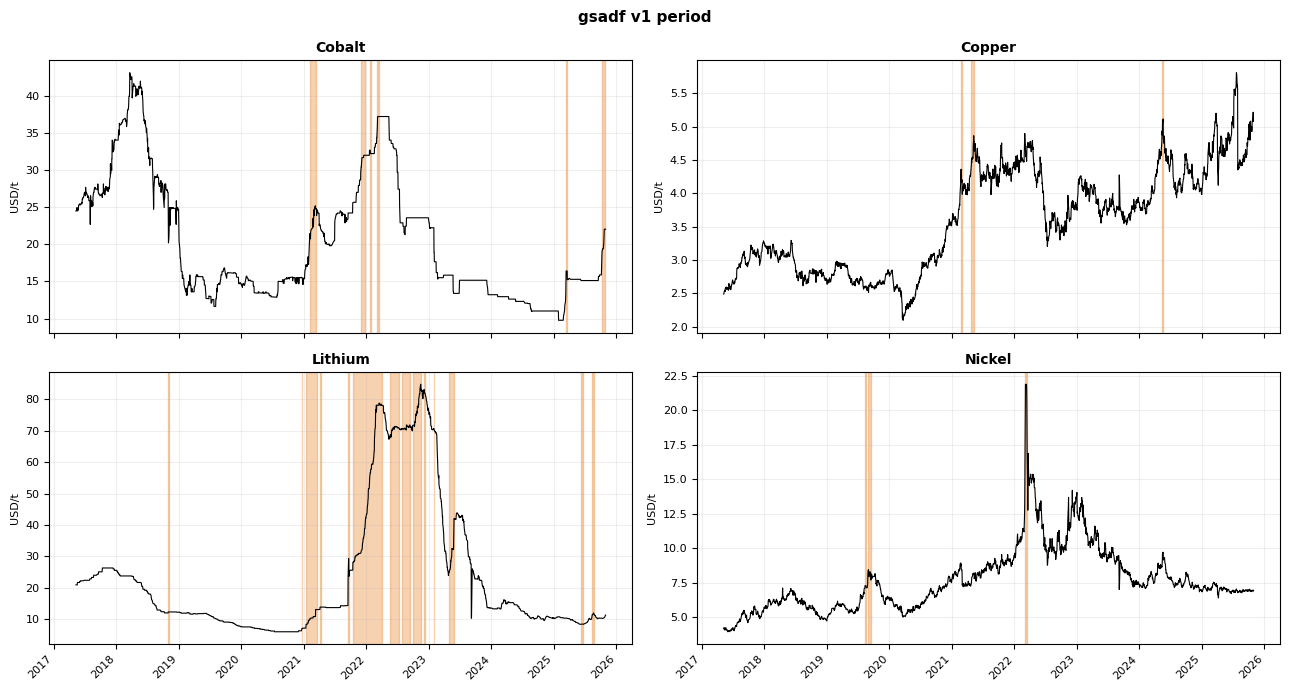

Saved → ../outputs/06_gsadf_v1_period_bubbles.png


In [4]:
V = 'gsadf_v1_period'
C = VARIANT_COLORS[V]

# 1a. Price chart with bubble periods
plot_bubbles_2x2(V, C, f'../outputs/06_{V}_bubbles.png')


Computing SHAP: LASSO on gsadf_v1_period × 4 metals ...


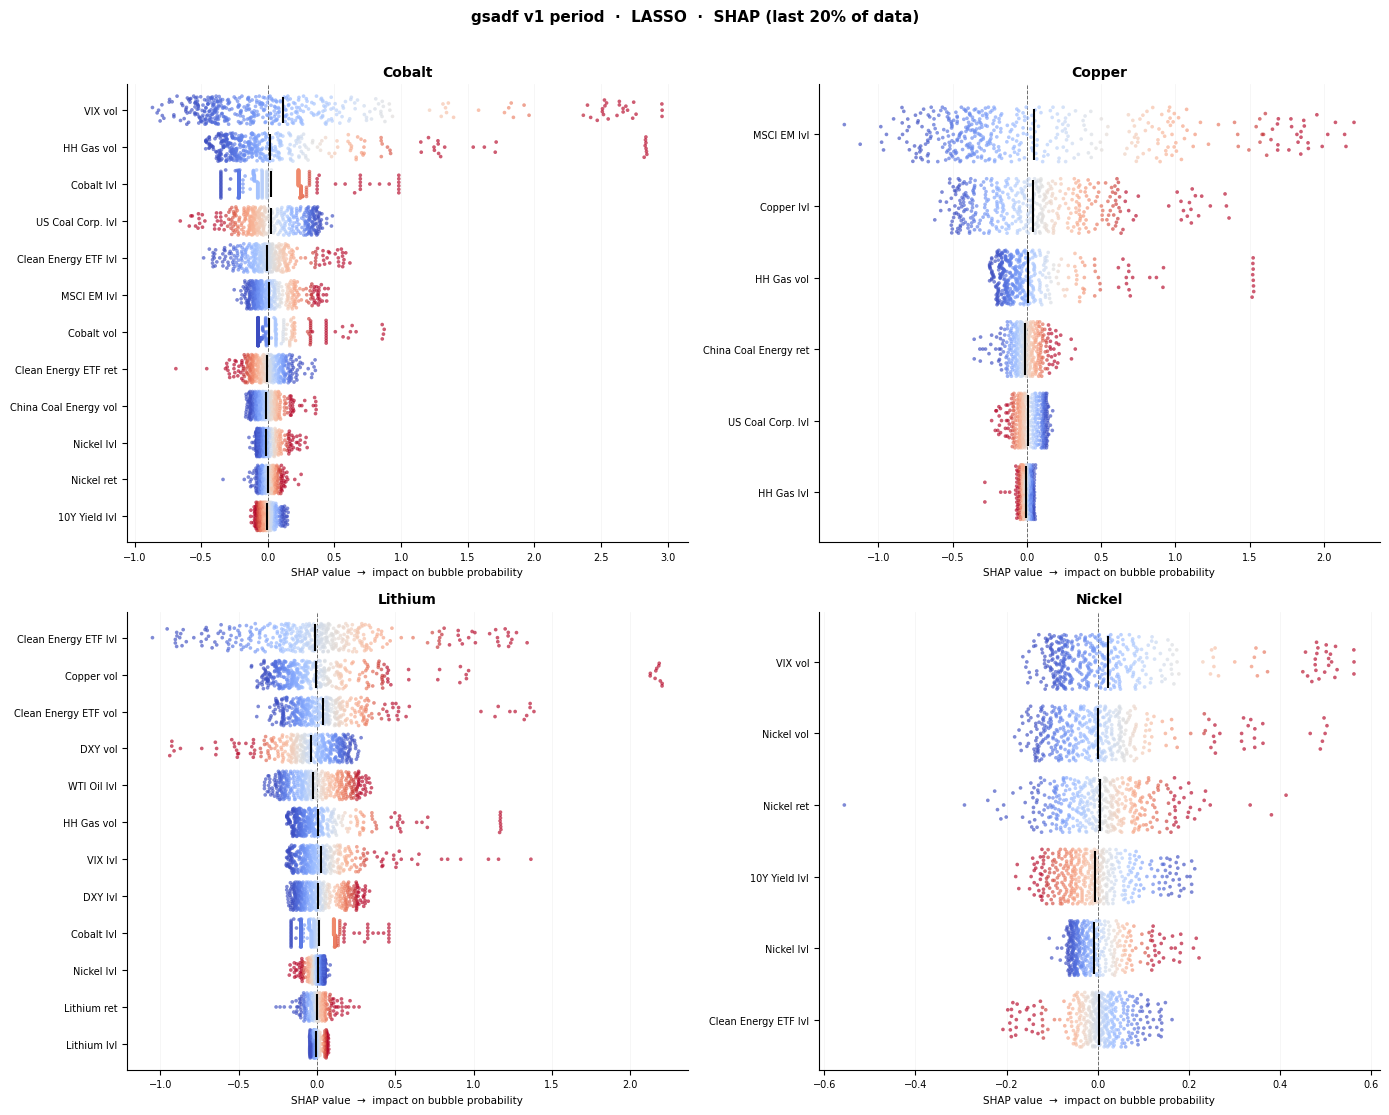

Saved → ../outputs/06_gsadf_v1_period_shap_lasso.png


In [5]:
# 1b. SHAP beeswarm — LASSO, all 4 metals
print(f'Computing SHAP: {GLOBAL_BEST_MODEL} on {V} × 4 metals ...')
plot_shap_beeswarm_panel(V, GLOBAL_BEST_MODEL,
                         f'../outputs/06_{V}_shap_{GLOBAL_BEST_MODEL.lower()}.png')


---
## Section 2 — `gsadf_updown_period`

`gsadf_updown_period` retains all GSADF-datestamped episodes regardless of price direction — unlike the OLS/V1 variants, it includes both the bubble inflation and the crash phase. Post-processing (gap-bridging and minimum duration) is applied identically. This broader labelling led to the best overall model performance on Lithium and Nickel (F1 0.75 and 0.90 respectively).

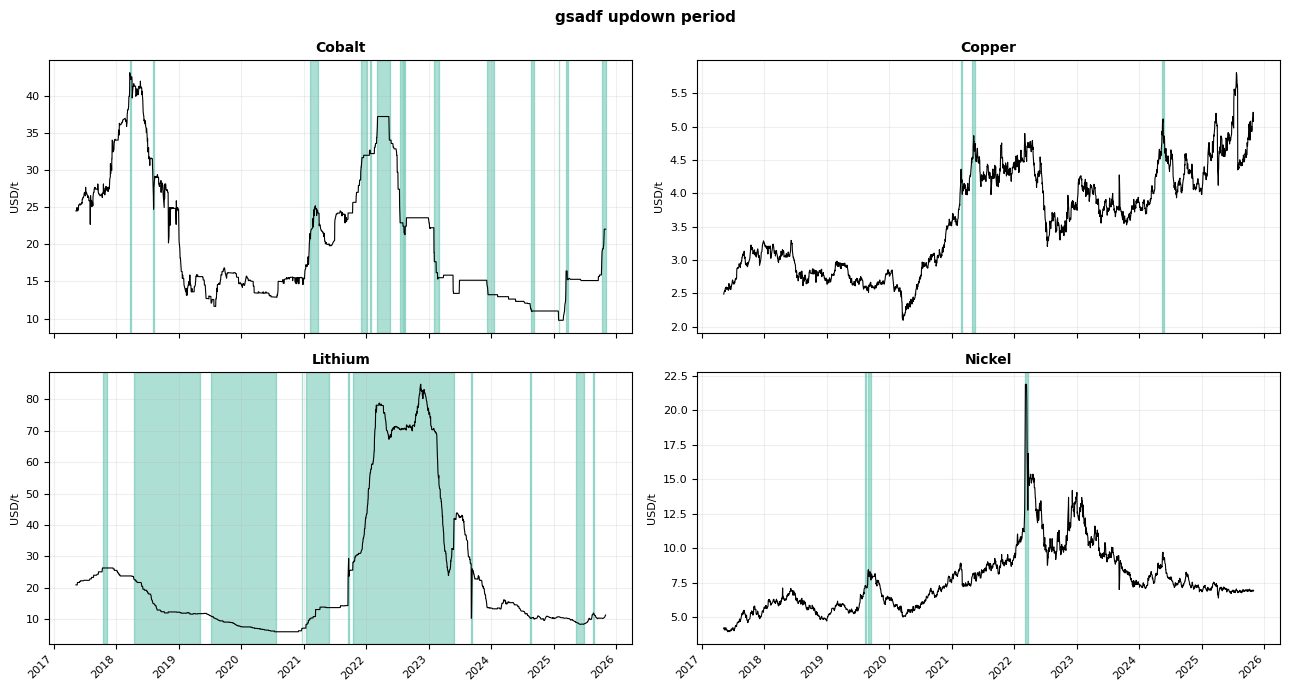

Saved → ../outputs/06_gsadf_updown_period_bubbles.png


In [6]:
V = 'gsadf_updown_period'
C = VARIANT_COLORS[V]

# 2a. Bubble chart
plot_bubbles_2x2(V, C, f'../outputs/06_{V}_bubbles.png')


Computing SHAP: LASSO on gsadf_updown_period × 4 metals ...


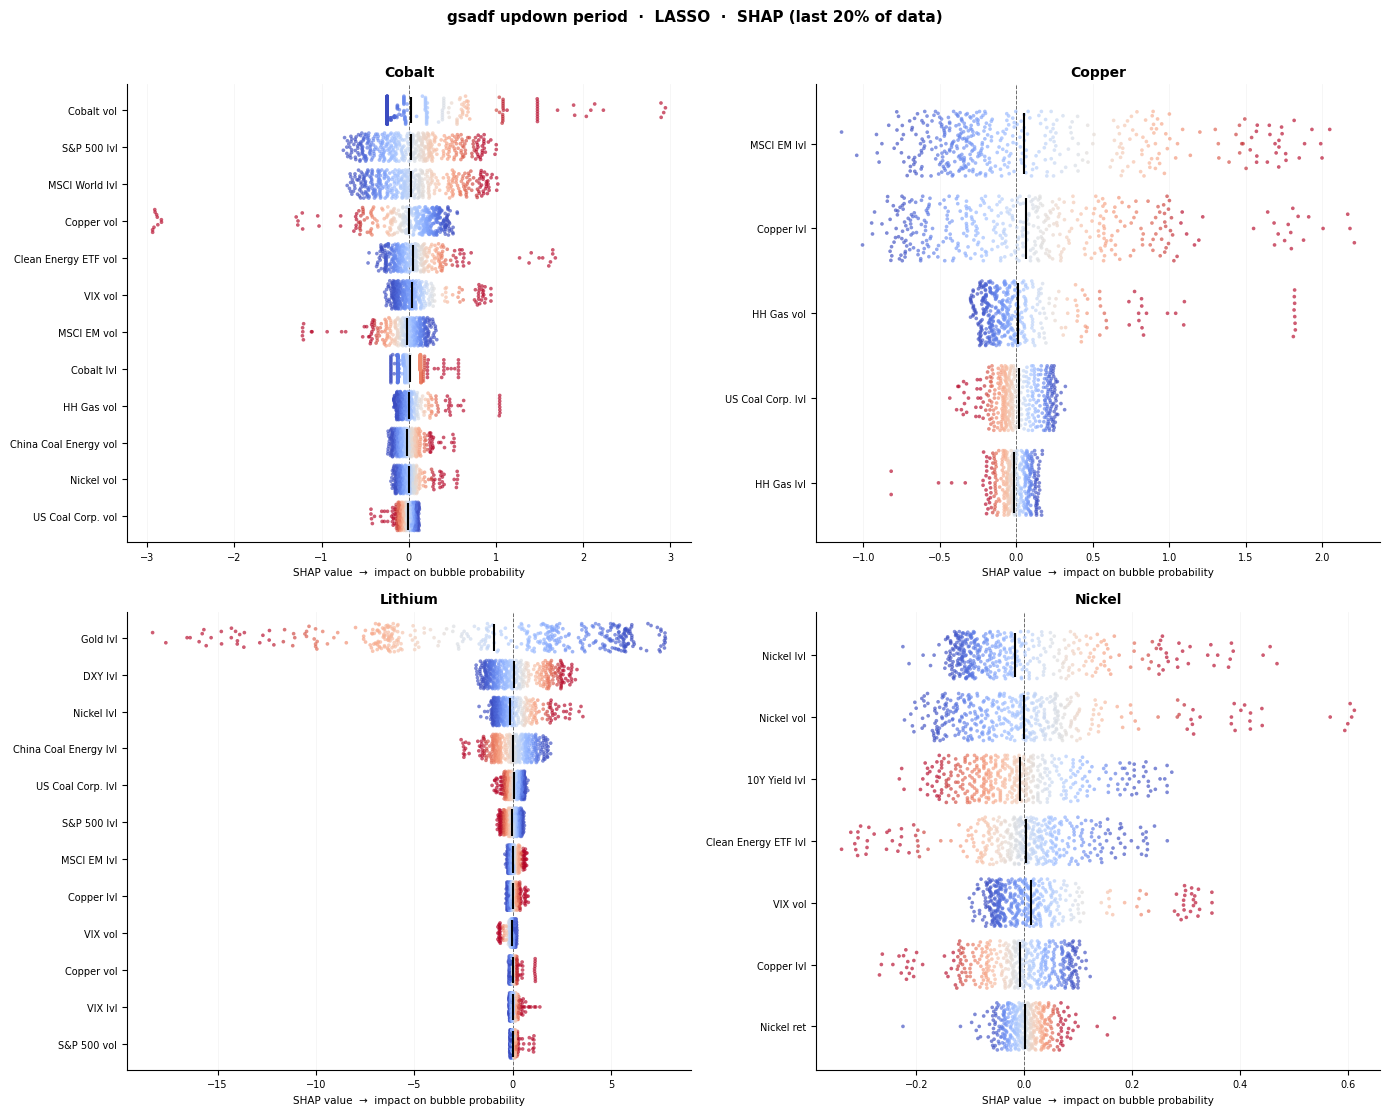

Saved → ../outputs/06_gsadf_updown_period_shap_lasso.png


In [7]:
# 2b. SHAP beeswarm — LASSO, all 4 metals
print(f'Computing SHAP: {GLOBAL_BEST_MODEL} on {V} × 4 metals ...')
plot_shap_beeswarm_panel(V, GLOBAL_BEST_MODEL,
                         f'../outputs/06_{V}_shap_{GLOBAL_BEST_MODEL.lower()}.png')


---
## Section 3 — `lppls_0.01_period`

`lppls_0.01_period` is the most permissive LPPLS variant: it flags days where the smoothed LPPLS confidence score exceeds just 1%, then applies the trend filter and morphological post-processing. The low threshold captures many more potential bubble days than the 0.10 or 0.20 variants, at the cost of more false positives. For Cobalt this is the top-performing variant overall (AUC 0.909 with LASSO).

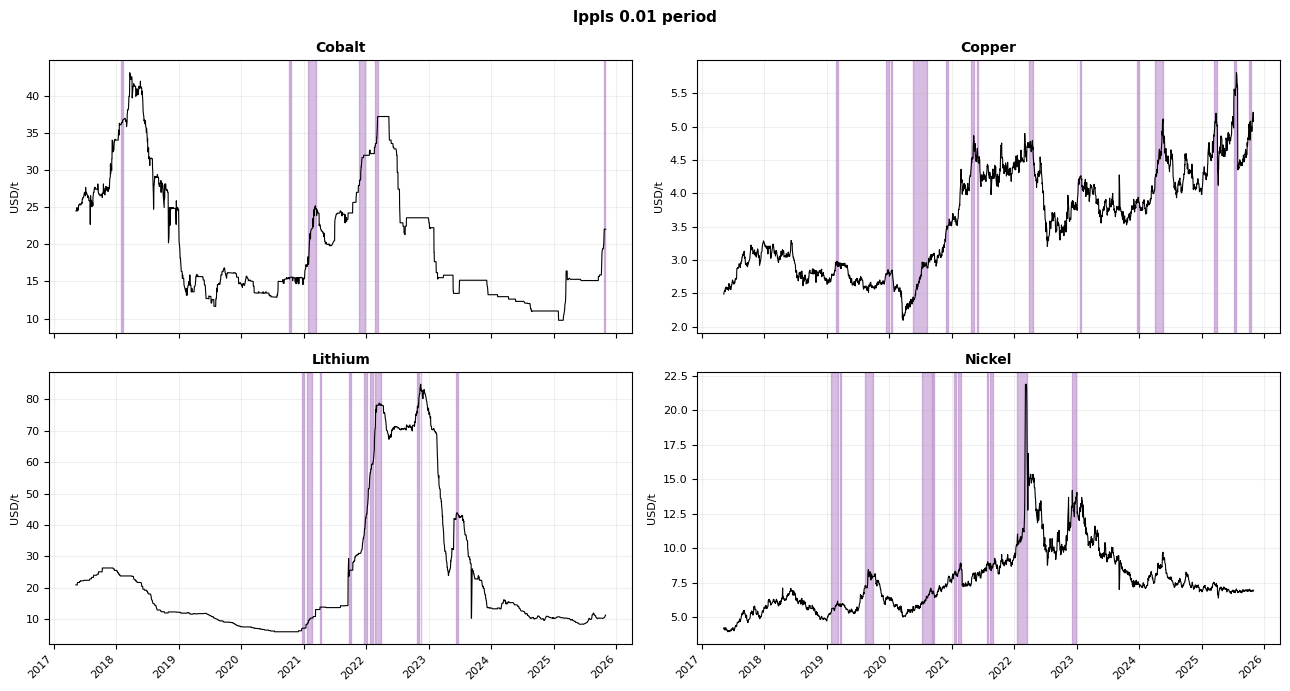

Saved → ../outputs/06_lppls_0.01_period_bubbles.png


In [8]:
V = 'lppls_0.01_period'
C = VARIANT_COLORS[V]

# 3a. Bubble chart
plot_bubbles_2x2(V, C, f'../outputs/06_{V}_bubbles.png')


Computing SHAP: LASSO on lppls_0.01_period × 4 metals ...


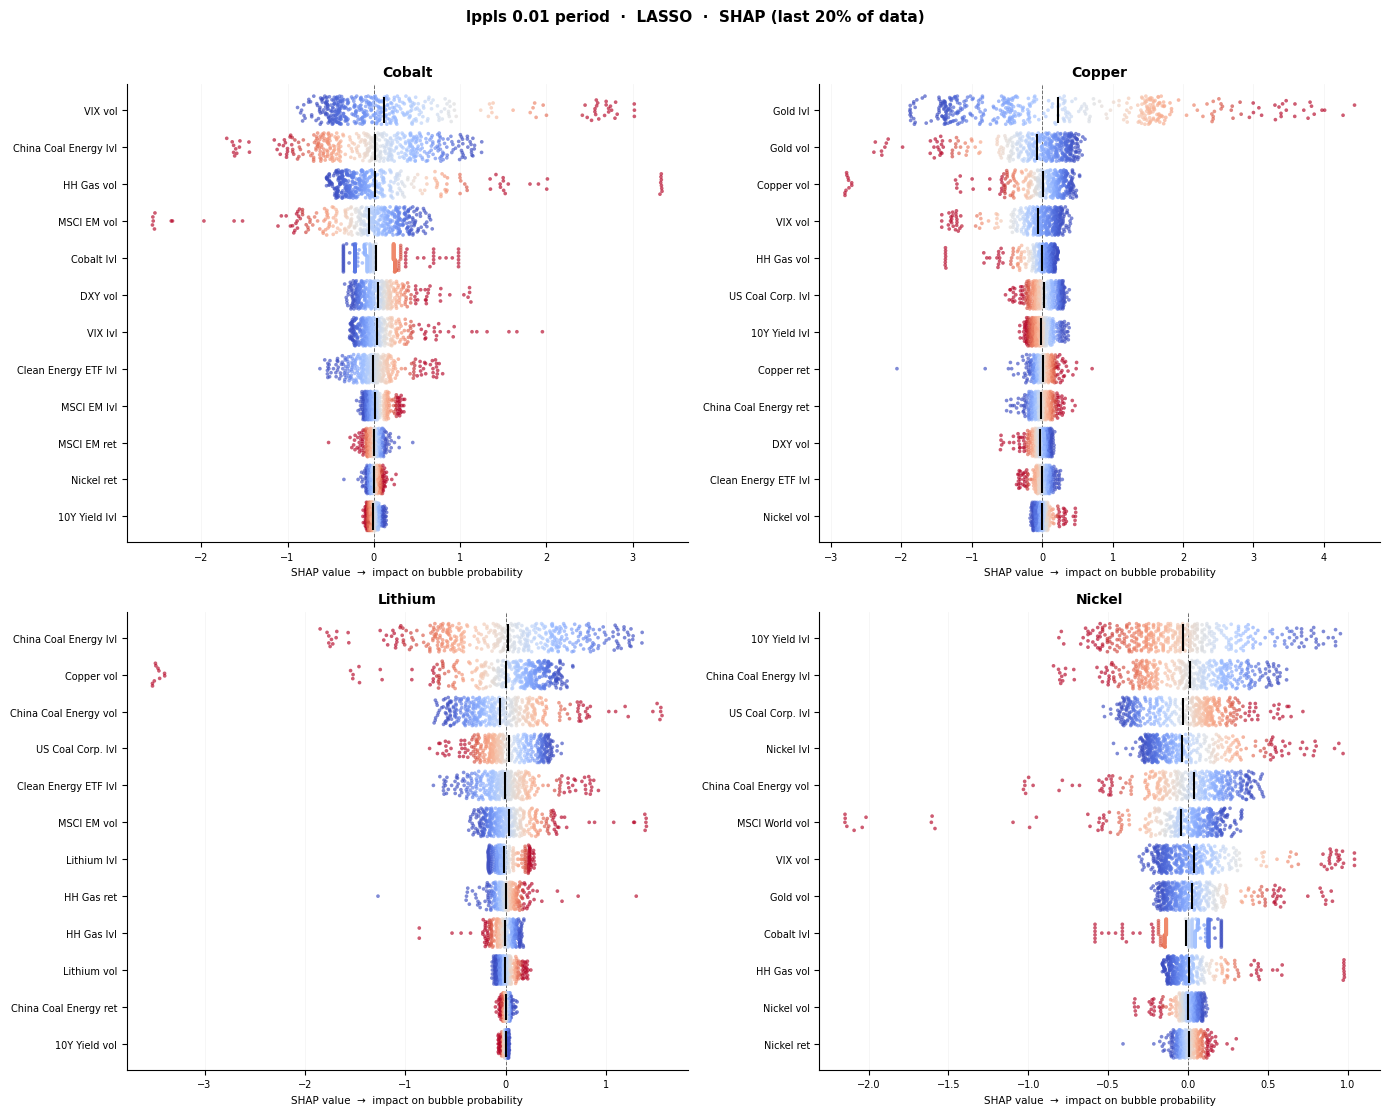

Saved → ../outputs/06_lppls_0.01_period_shap_lasso.png


In [9]:
# 3b. SHAP beeswarm — LASSO, all 4 metals
print(f'Computing SHAP: {GLOBAL_BEST_MODEL} on {V} × 4 metals ...')
plot_shap_beeswarm_panel(V, GLOBAL_BEST_MODEL,
                         f'../outputs/06_{V}_shap_{GLOBAL_BEST_MODEL.lower()}.png')


---
## Section 4 — `cusum_smoothed`

`cusum_smoothed` applies a 5-day rolling mean to the CUSUM log-return statistic before thresholding, smoothing out day-to-day noise while retaining multi-day exceedance runs. Unlike the GSADF and LPPLS variants, it requires no distributional assumption or model fitting — it is a purely nonparametric control-chart signal. Models here are trained using the CUSUM-smoothed flag as the prediction target, enabling SHAP to reveal which market features most reliably precede CUSUM-identified stress periods.

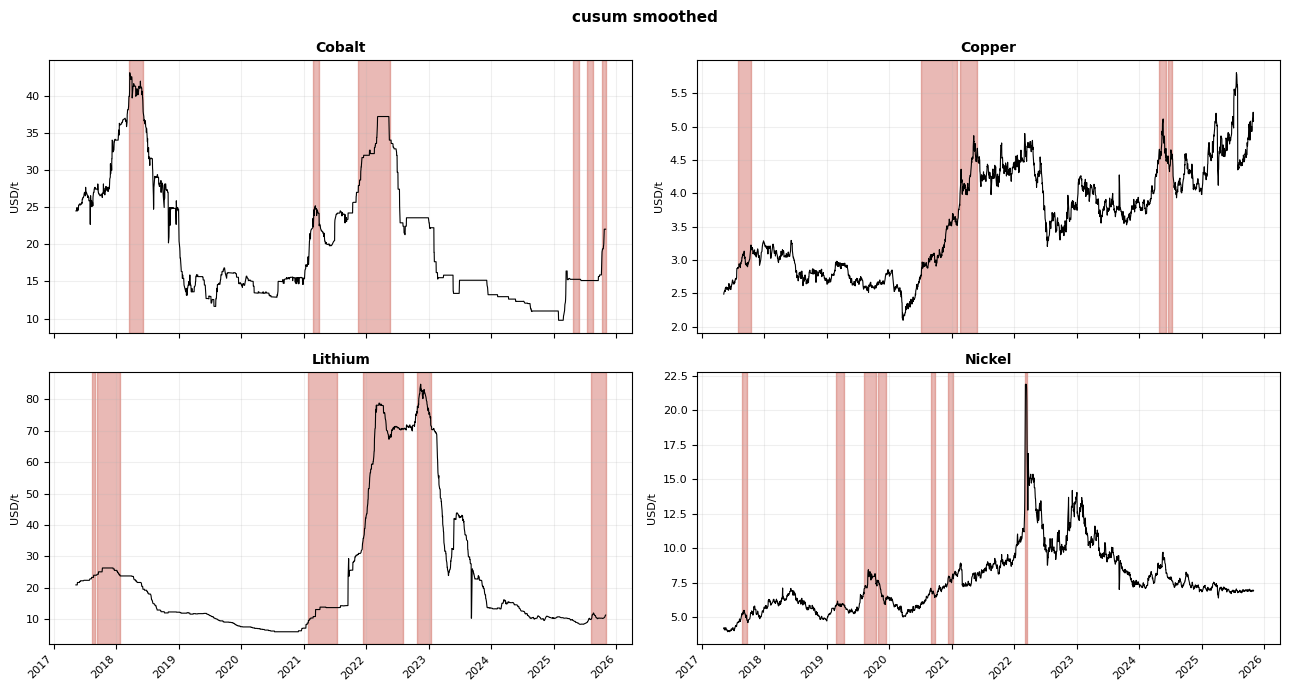

Saved → ../outputs/06_cusum_smoothed_bubbles.png


In [10]:
V = 'cusum_smoothed'
C = VARIANT_COLORS[V]

# 4a. Bubble chart
plot_bubbles_2x2(V, C, f'../outputs/06_{V}_bubbles.png')


Computing SHAP: LASSO on cusum_smoothed × 4 metals ...


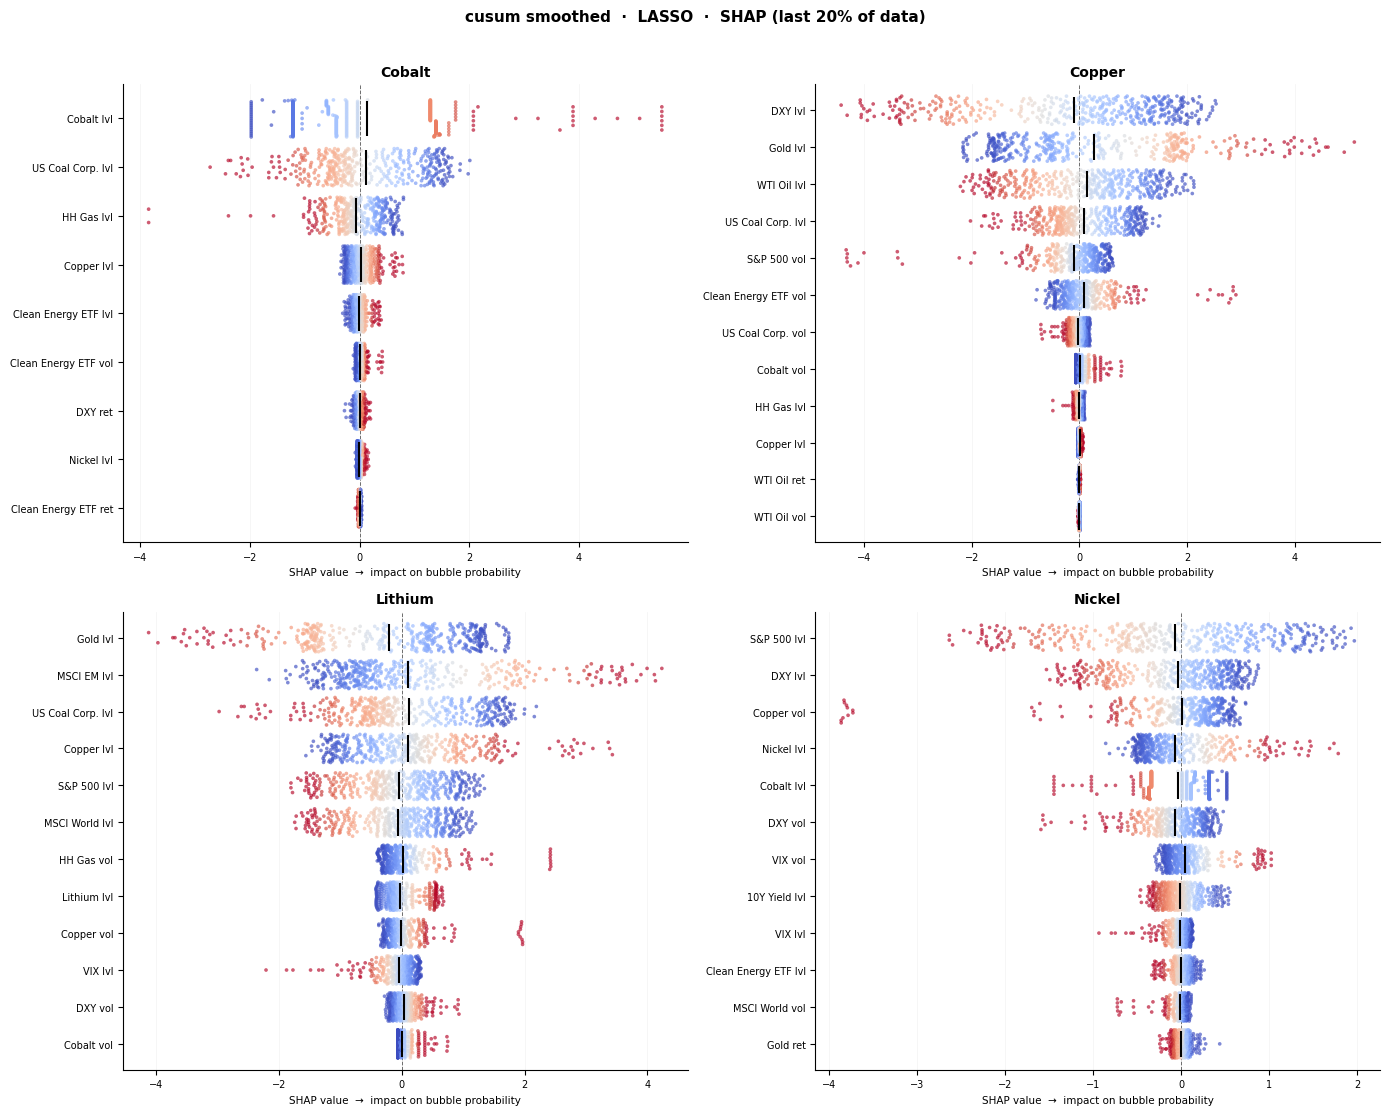

Saved → ../outputs/06_cusum_smoothed_shap_lasso.png


In [11]:
# 4b. SHAP beeswarm — LASSO, all 4 metals
print(f'Computing SHAP: {GLOBAL_BEST_MODEL} on {V} × 4 metals ...')
plot_shap_beeswarm_panel(V, GLOBAL_BEST_MODEL,
                         f'../outputs/06_{V}_shap_{GLOBAL_BEST_MODEL.lower()}.png')


In [12]:
# ── Load pre-computed mean |SHAP| summary ────────────────────────────────────
shap_csv = '../outputs/06_shap_mean_abs.csv'
if os.path.exists(shap_csv):
    df_shap_abs = pd.read_csv(shap_csv)
    print(f'Loaded {shap_csv}  ({len(df_shap_abs)} rows)')

    # Print top-5 per (variant, metal)
    print()
    for v in FOCUS_VARIANTS:
        print(f'{v}:')
        for metal in METALS:
            sub = df_shap_abs[(df_shap_abs.Variant == v) & (df_shap_abs.Metal == metal)]
            if sub.empty:
                print(f'  {metal:8s}: —')
                continue
            top5 = sub.nlargest(5, 'MeanAbsSHAP')
            parts = [f'{r.FriendlyName} ({r.MeanAbsSHAP:.4f})' for _, r in top5.iterrows()]
            print(f'  {metal:8s}: ' + '  |  '.join(parts))
        print()
else:
    df_shap_abs = None
    print(f'Note: {shap_csv} not found — SHAP summary plots will be skipped.')
    print('To generate it, run the SHAP computation notebook (07_presentation or equivalent).')


Loaded ../outputs/06_shap_mean_abs.csv  (180 rows)

gsadf_v1_period:
  Cobalt  : VIX vol (0.4375)  |  HH Gas vol (0.3346)  |  Cobalt lvl (0.2894)  |  Clean Energy ETF lvl (0.1893)  |  Cobalt vol (0.1255)
  Copper  : MSCI EM lvl (0.6248)  |  Copper lvl (0.3098)  |  HH Gas vol (0.1843)  |  HH Gas lvl (0.0371)
  Lithium : Gold lvl (0.5743)  |  Clean Energy ETF lvl (0.2869)  |  WTI Oil lvl (0.2347)  |  Clean Energy ETF vol (0.1933)  |  VIX lvl (0.1554)
  Nickel  : VIX vol (0.0969)  |  Nickel vol (0.0810)  |  Nickel ret (0.0730)  |  10Y Yield lvl (0.0612)  |  Nickel lvl (0.0476)

gsadf_updown_period:
  Cobalt  : Gold lvl (0.8766)  |  S&P 500 lvl (0.5931)  |  Cobalt vol (0.3819)  |  Cobalt lvl (0.2471)  |  Gold vol (0.1131)
  Copper  : MSCI EM lvl (0.6344)  |  Copper lvl (0.4832)  |  HH Gas vol (0.2083)  |  HH Gas lvl (0.0990)
  Lithium : Gold lvl (2.6005)  |  DXY lvl (1.2091)  |  S&P 500 lvl (0.7018)  |  WTI Oil lvl (0.5582)  |  MSCI EM lvl (0.4300)
  Nickel  : Nickel vol (0.0986)  |  Nicke

---
## Summary — Cross-Variant SHAP Comparison (LASSO, all 4 variants × 4 metals)

Using LASSO consistently across all combinations allows a direct apples-to-apples comparison of which features matter most for each detection method.

Building cross-variant SHAP summary panel from CSV ...


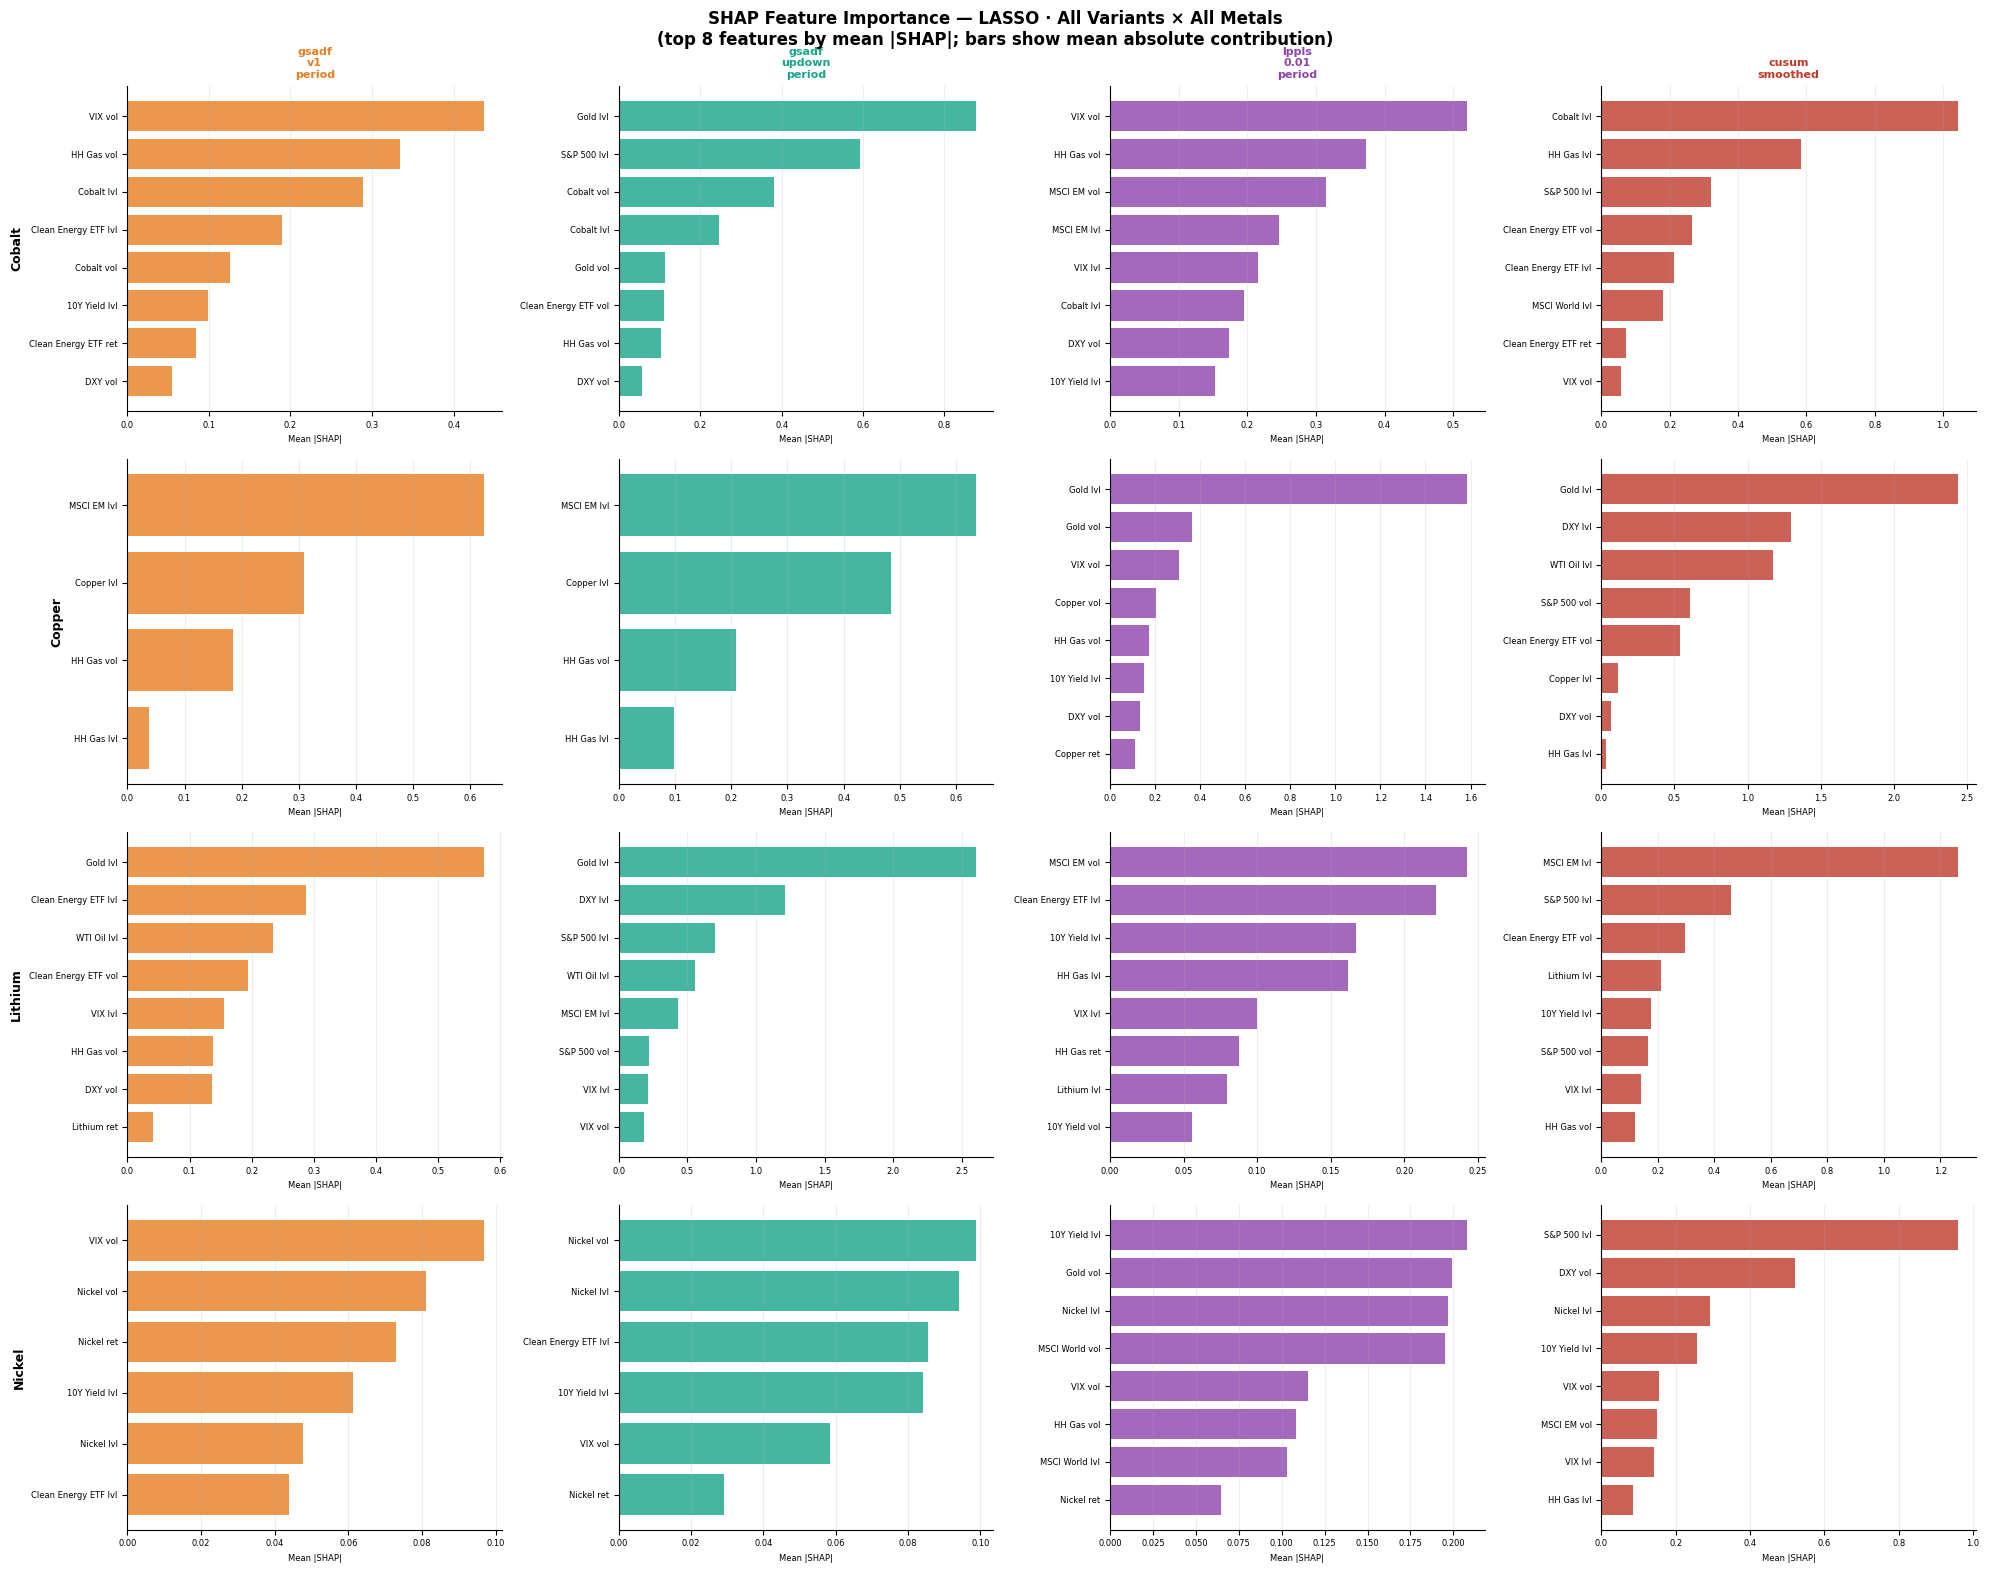

Saved → ../outputs/06_shap_crossvariant_summary.png


In [13]:
# 4-row × 4-col grid: rows = metals, cols = variants
# Each cell: horizontal bar chart (top-8 features by mean |SHAP|, from CSV)
if df_shap_abs is None:
    print('Skipping: 06_shap_mean_abs.csv not found.')
else:
    print('Building cross-variant SHAP summary panel from CSV ...')

    fig, axes = plt.subplots(4, 4, figsize=(20, 16))
    metals_list = list(METALS.keys())

    for col_i, v in enumerate(FOCUS_VARIANTS):
        for row_i, metal in enumerate(metals_list):
            ax = axes[row_i][col_i]
            sub = (df_shap_abs[(df_shap_abs.Variant == v) & (df_shap_abs.Metal == metal)]
                   .nlargest(8, 'MeanAbsSHAP')
                   .sort_values('MeanAbsSHAP'))  # ascending so largest is at top
            if sub.empty:
                ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                        transform=ax.transAxes, fontsize=8)
            else:
                ax.barh(sub['FriendlyName'], sub['MeanAbsSHAP'],
                        color=VARIANT_COLORS[v], alpha=0.8)
                ax.tick_params(labelsize=6)
                ax.set_xlabel('Mean |SHAP|', fontsize=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(axis='x', alpha=0.2)
            if row_i == 0:
                ax.set_title(v.replace('_', '\n'), fontsize=8, fontweight='bold',
                             color=VARIANT_COLORS[v])
            if col_i == 0:
                ax.set_ylabel(metal, fontsize=9, fontweight='bold')

    plt.suptitle(
        'SHAP Feature Importance — LASSO · All Variants × All Metals\n'
        '(top 8 features by mean |SHAP|; bars show mean absolute contribution)',
        fontsize=12, fontweight='bold')
    plt.tight_layout()
    save_p = '../outputs/06_shap_crossvariant_summary.png'
    plt.savefig(save_p, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {save_p}')


## 6. Mean |SHAP| — Top Features per Variant × Metal

Horizontal bar charts showing mean absolute SHAP value per feature for each of the 4 focus variants × 4 metals (LASSO global model).  Longer bar = stronger average influence on bubble-probability prediction.

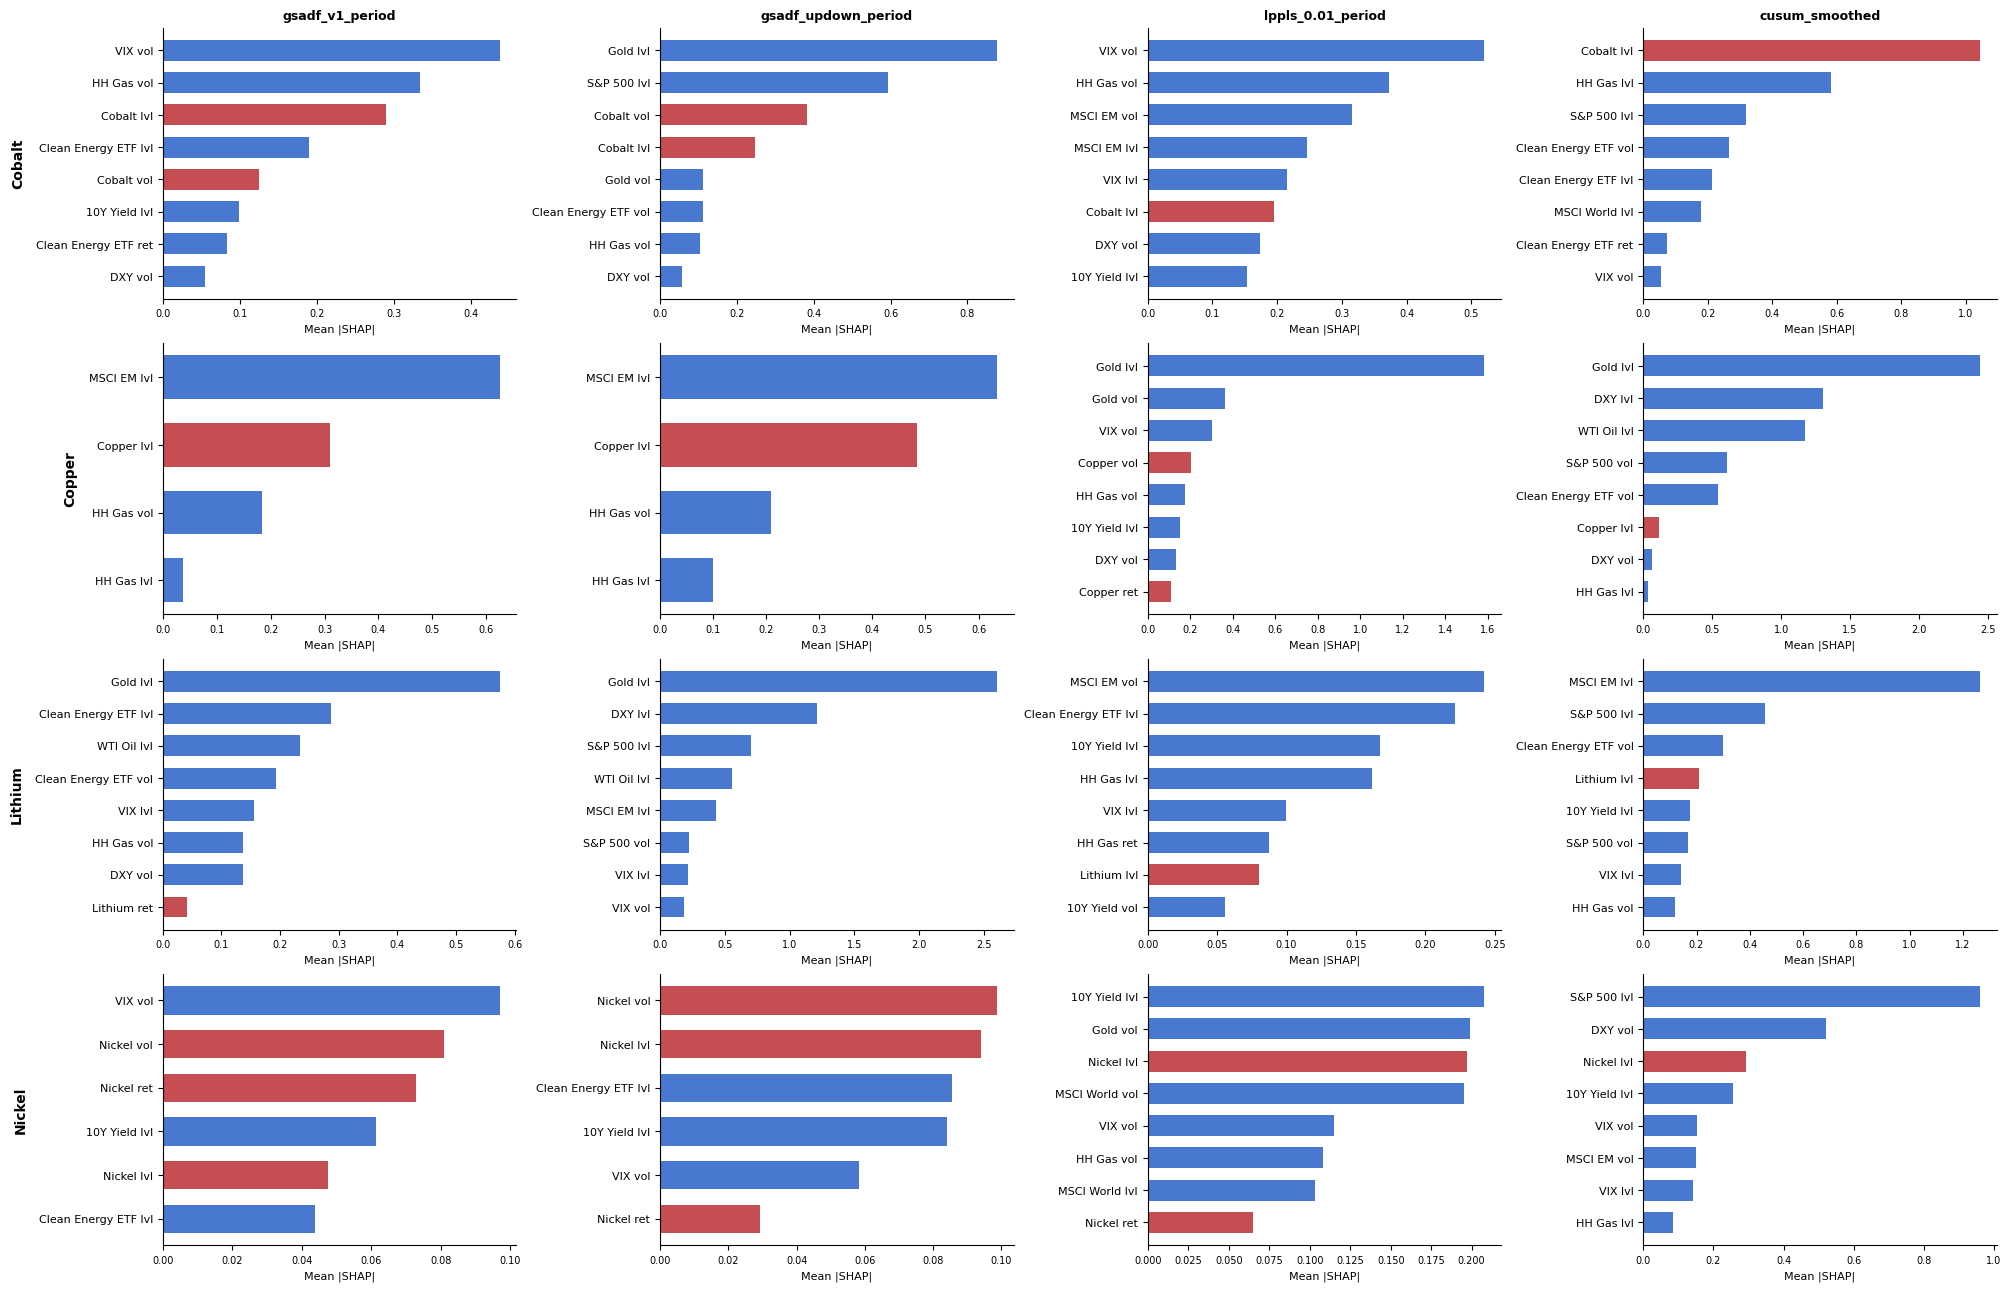

Saved → ../outputs/06_shap_mean_abs_plot.png


In [14]:
if df_shap_abs is None:
    print('Skipping: 06_shap_mean_abs.csv not found.')
else:
    metals_order   = ['Cobalt', 'Copper', 'Lithium', 'Nickel']
    variant_order  = FOCUS_VARIANTS
    TOP_N          = 8
    BAR_COLOR      = '#4878CF'
    EMPH_COLOR     = '#C44E52'               # highlight own-metal feature

    fig, axes = plt.subplots(
        len(metals_order), len(variant_order),
        figsize=(5 * len(variant_order), 3.2 * len(metals_order)),
        constrained_layout=True,
    )

    for row_i, metal in enumerate(metals_order):
        for col_i, variant in enumerate(variant_order):
            ax = axes[row_i, col_i]
            sub = (df_shap_abs[(df_shap_abs.Metal == metal) & (df_shap_abs.Variant == variant)]
                   .nlargest(TOP_N, 'MeanAbsSHAP')
                   .sort_values('MeanAbsSHAP'))

            if sub.empty:
                ax.axis('off'); continue

            colors = [EMPH_COLOR if METALS[metal] in f else BAR_COLOR
                      for f in sub['Feature']]
            ax.barh(sub['FriendlyName'], sub['MeanAbsSHAP'], color=colors, height=0.65)
            ax.set_xlabel('Mean |SHAP|', fontsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.tick_params(axis='x', labelsize=7)
            ax.spines[['top', 'right']].set_visible(False)

            if row_i == 0:
                ax.set_title(variant, fontsize=9, fontweight='bold')
            if col_i == 0:
                ax.set_ylabel(metal, fontsize=10, fontweight='bold', labelpad=8)

    save_p = '../outputs/06_shap_mean_abs_plot.png'
    fig.savefig(save_p, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved → {save_p}')
